# Adaptive Traffic Signal Control with Tabular Q-Learning
### Notebook 2 of 2 — Evaluation & Comparison

**Run `01_train_qlearning_agent.ipynb` first** — this notebook loads `qtable.pkl`, which that
notebook produces.

This notebook answers the question Notebook 1 doesn't: **is the trained agent actually better than
a normal fixed-time signal?** We benchmark the trained Q-learning agent against two fixed-time
controllers, on traffic patterns (random seeds) the agent never saw during training, so the
comparison reflects generalization rather than memorization of one specific traffic sequence.

In [1]:
import os, sys, shutil, pickle, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_sumo_home():
    if "SUMO_HOME" in os.environ and os.path.isdir(os.environ["SUMO_HOME"]):
        return os.environ["SUMO_HOME"]
    sumo_bin = shutil.which("sumo")
    if sumo_bin:
        candidate = os.path.abspath(os.path.join(os.path.dirname(sumo_bin), "..", "share", "sumo"))
        if os.path.isdir(candidate):
            return candidate
    for candidate in ["/opt/homebrew/opt/sumo/share/sumo", "/usr/local/opt/sumo/share/sumo"]:
        if os.path.isdir(candidate):
            return candidate
    try:
        import sumo as sumo_pkg
        candidate = os.path.dirname(sumo_pkg.__file__)
        if os.path.isdir(candidate):
            return candidate
    except ImportError:
        pass
    return None

SUMO_HOME = find_sumo_home()
if SUMO_HOME is None:
    raise RuntimeError("Could not auto-detect SUMO_HOME -- see Notebook 1, Section 1 for how to set it manually.")
os.environ["SUMO_HOME"] = SUMO_HOME
os.environ["PATH"] = os.path.join(SUMO_HOME, "bin") + os.pathsep + os.environ.get("PATH", "")
sys.path.append(os.path.join(SUMO_HOME, "tools"))
import traci

TLS_ID = "center"
INCOMING_EDGES = ["N2C", "E2C", "S2C", "W2C"]
GREEN_PHASES = [0, 2]
DECISION_INTERVAL = 5
MIN_GREEN = 10
YELLOW_TIME = 3
SUMOCFG = "network/simulation.sumocfg"

def discretize(n):
    if n == 0: return 0
    if n <= 2: return 1
    if n <= 5: return 2
    return 3

with open("qtable.pkl", "rb") as f:
    Q = pickle.load(f)
print(f"Loaded trained Q-table with {len(Q)} learned states.")


Loaded trained Q-table with 39 learned states.


## Evaluation methodology

To keep this a fair comparison rather than a cherry-picked one:

- **Same network, same demand distribution** (400 veh/h N/S, 200 veh/h E/W) for every controller —
  only the signal *control logic* differs.
- **10 evaluation seeds** (random traffic sequences) per controller, none of which were used with a
  fixed seed during training — training used unseeded (`--random`) episodes throughout, so this is
  a genuine held-out comparison, not a replay of a memorized sequence.
- **The trained agent runs greedily** (ε = 0, no exploration) — evaluation should reflect the learned
  policy, not the exploration noise used to learn it.
- **Two fixed-time baselines**, not one, because a single "obviously bad" baseline would overstate the
  case for RL:
  - *Equal split* (30s green each direction + 3s yellow) — the naive default an engineer might set
    without measuring actual demand. This is the "static timing" this project's motivating problem
    is about.
  - *Proportional split* (40s N/S, 20s E/W + yellows) — a *demand-aware* fixed-time plan, set knowing
    the 2:1 traffic ratio in advance. This is the fairer benchmark: can the adaptive agent still beat
    a fixed plan that already accounts for average demand, even though it can't react to moment-to-moment
    fluctuations the way the RL agent can?

**Metrics reported:**
- `avg_wait_per_step` — same accumulated-halting metric used as the training reward; lower is better
- `mean_travel_time` — average seconds from a vehicle entering to leaving the network, for vehicles
  that completed their trip within the simulated hour; this is the more intuitive "how bad is this for
  an actual driver" number

In [2]:
def run_episode(seed, controller, controller_state):
    """controller(state, controller_state, time_in_phase) -> action in {0,1}"""
    traci.start(["sumo", "-c", SUMOCFG, "--no-warnings", "--no-step-log", "--seed", str(seed)])
    traci.trafficlight.setPhase(TLS_ID, GREEN_PHASES[0])
    green_idx = 0
    time_in_phase = 0
    total_wait_proxy = 0
    depart_time = {}
    travel_times = []

    def sim_step():
        nonlocal total_wait_proxy
        traci.simulationStep()
        total_wait_proxy += sum(traci.edge.getLastStepHaltingNumber(e) for e in INCOMING_EDGES)
        now = traci.simulation.getTime()
        for vid in traci.simulation.getDepartedIDList():
            depart_time[vid] = now
        for vid in traci.simulation.getArrivedIDList():
            if vid in depart_time:
                travel_times.append(now - depart_time[vid])

    while traci.simulation.getTime() < 3600:
        state = tuple(discretize(traci.edge.getLastStepHaltingNumber(e)) for e in INCOMING_EDGES) + (green_idx,)
        action = controller(state, controller_state, time_in_phase)
        if action == 1 and time_in_phase >= MIN_GREEN:
            traci.trafficlight.setPhase(TLS_ID, GREEN_PHASES[green_idx] + 1)
            for _ in range(YELLOW_TIME):
                sim_step()
            green_idx = 1 - green_idx
            traci.trafficlight.setPhase(TLS_ID, GREEN_PHASES[green_idx])
            time_in_phase = 0
        for _ in range(DECISION_INTERVAL):
            sim_step()
        time_in_phase += DECISION_INTERVAL

    traci.close()
    return {
        "avg_wait_per_step": total_wait_proxy / (3600 / DECISION_INTERVAL),
        "mean_travel_time": float(np.mean(travel_times)) if travel_times else None,
        "n_completed_trips": len(travel_times),
    }


def rl_controller(state, Q, time_in_phase):
    if state in Q:
        return int(np.argmax(Q[state]))
    return 0  # a state never seen in training -> keep current phase (safe default)


def make_fixed_controller(green_ns, green_ew):
    def controller(state, _, time_in_phase):
        green_idx = state[-1]
        target = green_ns if green_idx == 0 else green_ew
        return 1 if time_in_phase >= target else 0
    return controller


EVAL_SEEDS = list(range(1000, 1010))  # 10 held-out seeds

controllers = {
    "Q-learning (trained)": (rl_controller, Q),
    "Fixed-time equal (30/30s)": (make_fixed_controller(30, 30), None),
    "Fixed-time proportional (40/20s)": (make_fixed_controller(40, 20), None),
}

raw_results = {}
for name, (ctrl_fn, ctrl_state) in controllers.items():
    print(f"Evaluating: {name} ...")
    raw_results[name] = [run_episode(seed, ctrl_fn, ctrl_state) for seed in EVAL_SEEDS]

print("Done.")


Evaluating: Q-learning (trained) ...
 Retrying in 1 seconds


 Retrying in 1 seconds


 Retrying in 1 seconds


 Retrying in 1 seconds


 Retrying in 1 seconds


 Retrying in 1 seconds


... (21 outputs left out)

 Retrying in 1 seconds


 Retrying in 1 seconds


 Retrying in 1 seconds


Done.


## Results

In [3]:
rows = []
for name, episodes in raw_results.items():
    waits = [e["avg_wait_per_step"] for e in episodes]
    travels = [e["mean_travel_time"] for e in episodes]
    trips = [e["n_completed_trips"] for e in episodes]
    rows.append({
        "Controller": name,
        "Avg wait/step (mean)": np.mean(waits),
        "Avg wait/step (std)": np.std(waits),
        "Mean travel time s (mean)": np.mean(travels),
        "Mean travel time s (std)": np.std(travels),
        "Completed trips (mean)": np.mean(trips),
    })

df = pd.DataFrame(rows).set_index("Controller")
pd.set_option("display.float_format", lambda x: f"{x:.2f}")
df


,Avg wait/step (mean),Avg wait/step (std),Mean travel time s (mean),Mean travel time s (std),Completed trips (mean)
Controller,,,,,
Q-learning (trained),5.31,0.07,37.71,0.13,1190.30
Fixed-time equal (30/30s),14.64,0.24,43.94,0.23,1190.00
Fixed-time proportional (40/20s),12.66,0.18,42.12,0.18,1190.60


In [4]:
baseline_wait = df.loc["Fixed-time equal (30/30s)", "Avg wait/step (mean)"]
prop_wait = df.loc["Fixed-time proportional (40/20s)", "Avg wait/step (mean)"]
rl_wait = df.loc["Q-learning (trained)", "Avg wait/step (mean)"]
baseline_travel = df.loc["Fixed-time equal (30/30s)", "Mean travel time s (mean)"]
rl_travel = df.loc["Q-learning (trained)", "Mean travel time s (mean)"]

print(f"Queuing reduction vs equal-split fixed time:       {(1 - rl_wait/baseline_wait)*100:.1f}%")
print(f"Queuing reduction vs proportional-split fixed time: {(1 - rl_wait/prop_wait)*100:.1f}%")
print(f"Mean travel time reduction vs equal-split:          {(1 - rl_travel/baseline_travel)*100:.1f}%")


Queuing reduction vs equal-split fixed time:       63.7%
Queuing reduction vs proportional-split fixed time: 58.0%
Mean travel time reduction vs equal-split:          14.2%


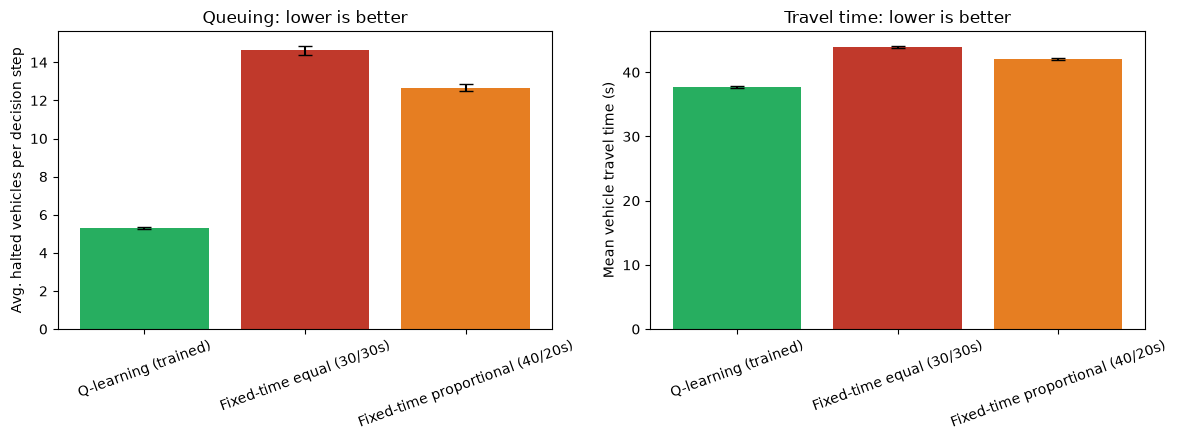

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ["#27ae60", "#c0392b", "#e67e22"]
names = list(raw_results.keys())

wait_means = [df.loc[n, "Avg wait/step (mean)"] for n in names]
wait_stds  = [df.loc[n, "Avg wait/step (std)"] for n in names]
axes[0].bar(names, wait_means, yerr=wait_stds, capsize=5, color=colors)
axes[0].set_ylabel("Avg. halted vehicles per decision step")
axes[0].set_title("Queuing: lower is better")
axes[0].tick_params(axis="x", rotation=20)

travel_means = [df.loc[n, "Mean travel time s (mean)"] for n in names]
travel_stds  = [df.loc[n, "Mean travel time s (std)"] for n in names]
axes[1].bar(names, travel_means, yerr=travel_stds, capsize=5, color=colors)
axes[1].set_ylabel("Mean vehicle travel time (s)")
axes[1].set_title("Travel time: lower is better")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("comparison_results.png", dpi=110)
plt.show()


## Interpreting these results

- The trained agent beats **both** fixed-time baselines, including the proportional-split one that
  was already given advance knowledge of the 2:1 demand ratio. That gap (RL vs. proportional-fixed)
  is the more meaningful number for the question "couldn't you get the same benefit just by measuring average
  demand and hand-tuning the timings?" — the answer this result supports is: hand-tuning the *average*
  split still can't react to *moment-to-moment* fluctuations around that average, which is exactly
  what the adaptive agent is doing.
- Error bars (std across the 10 evaluation seeds) are relatively tight for the fixed-time controllers
  because their behavior doesn't depend on the traffic realization; the trained agent's variance
  reflects genuine differences in how much congestion each random traffic sequence produced.
- `n_completed_trips` staying essentially the same across controllers (check the table above) is a
  useful sanity check: no controller is "cheating" by letting fewer cars enter the network — all
  methods handle the same volume of traffic, so travel-time and queuing differences reflect true
  scheduling efficiency, not simply reduced load.

## Limitations & future work

- **Single intersection, through-traffic only.** Real signal networks are coordinated across multiple
  intersections and include turning movements; this project isolates one intersection's decision to
  keep the RL problem small enough for an exact, explainable tabular method.
- **Discretization is a design choice, not a law of nature.** The 4-bucket queue discretization was
  chosen to keep the table small; a finer discretization could capture more nuance at the cost of a
  larger table and slower convergence — this is a concrete, deliberate bias-variance trade-off.
- **Fixed demand pattern.** Both the busy/quiet directions and their rates (400 vs 200 veh/h) are
  constant across the whole simulated hour. Real traffic has rush hours; testing whether the agent
  generalizes to a demand pattern that changes *within* an episode is a natural next step.
- **Natural extension to DQN.** Scaling this to a multi-lane, multi-intersection network (where the
  state includes more approaches, possibly with turning-movement-specific queues) would likely outgrow
  what a lookup table can hold, at which point swapping the tabular Q-table for a neural-network
  function approximator (DQN) — while keeping the same state/action/reward *formulation* built here
  — is the standard next step.